# Praktik 1. Menilai Hasil Pan-sharpening

Di QGIS kita sudah menajamkan Sentinel-2 dengan foto udara dan dengan bayangan medan LiDAR. Keduanya tampak lebih tajam. Pertanyaannya: apakah nilainya masih benar? Notebook ini mengujinya dengan protokol Wald et al. (1997).

Gagasannya sederhana. Kebenaran pada 2,5 m tidak kita miliki, jadi percobaan diturunkan satu tingkat: Sentinel-2 dikasarkan dari 10 m ke 40 m, data detail dari 2,5 m ke 10 m, lalu hasil penajaman ke 10 m dibandingkan dengan Sentinel-2 10 m yang asli.

## 1. Menyiapkan data

In [1]:
import os, sys
if 'google.colab' in sys.modules:
    !pip -q install rasterio
    from google.colab import drive
    drive.mount('/content/drive')
    os.chdir('/content/drive/MyDrive/Pelatihan/data/praktik-1')   # sesuaikan dengan lokasi folder Anda
os.makedirs('hasil', exist_ok=True)
print('Folder kerja:', os.path.basename(os.getcwd()))

Folder kerja: praktik-1


In [2]:
import numpy as np
import pandas as pd
import rasterio
from rasterio.enums import Resampling
from rasterio.features import geometry_mask
from rasterio.warp import reproject
from scipy.ndimage import uniform_filter, zoom
import warnings
warnings.filterwarnings('ignore', category=RuntimeWarning)   # sel kosong di luar batas Sub-DAS
import matplotlib.pyplot as plt

X0, Y1, K = 396260, 9166410, 2.5
# Grid 2,5 m berimpit dengan grid 10 m Sentinel-2 dan mencakup batas Bompon
with rasterio.open('sentinel2_l2a_20250721_10m.tif') as src:
    T10 = src.transform
    CRS = src.crs
    c0 = int((396260 - T10.c) // 10); c1 = int(np.ceil((397780 - T10.c) / 10))
    r0 = int((T10.f - 9166410) // 10); r1 = int(np.ceil((T10.f - 9163190) / 10))
    s2 = src.read(window=((r0, r1), (c0, c1)))
from rasterio.transform import from_origin
xmin, ymaks = T10.c + c0 * 10, T10.f - r0 * 10
T = from_origin(xmin, ymaks, 2.5, 2.5)
baris, kolom = (r1 - r0) * 4, (c1 - c0) * 4
print('Sentinel-2', s2.shape, '| grid detail', baris, 'x', kolom)

def ke_detail(jalur, kanal=1, metode=Resampling.average):
    hasil = np.full((baris, kolom), np.nan, 'float32')
    with rasterio.open(jalur) as src:
        reproject(rasterio.band(src, kanal), hasil, dst_transform=T, dst_crs=CRS, dst_nodata=np.nan, resampling=metode)
    return hasil

fu = np.stack([ke_detail('foto_udara_rgb_1m.tif', b) for b in (1, 2, 3)])
pan_fu = fu.mean(axis=0)
dtm = ke_detail('LiDAR_Kalijambe_Bompon_20222023.tif')
def bayangan(z, az=315, alt=45, sel=2.5):
    gy, gx = np.gradient(z, sel)
    lereng = np.arctan(np.hypot(gx, gy)); arah = np.arctan2(-gx, gy)
    a, b = np.radians(360 - az + 90), np.radians(alt)
    return np.clip(np.sin(b) * np.cos(lereng) + np.cos(b) * np.sin(lereng) * np.cos(a - arah), 0, 1)
pan_hs = bayangan(dtm) * 255
sah = np.isfinite(pan_fu) & np.isfinite(pan_hs)
# piksel 10 m yang seluruh 4 x 4 sel detailnya sah
sah10 = sah.reshape(r1 - r0, 4, c1 - c0, 4).all(axis=(1, 3))
sah40 = sah10[: (sah10.shape[0] // 4) * 4, : (sah10.shape[1] // 4) * 4]
print('Piksel 10 m sah:', int(sah10.sum()), '| korelasi pan foto udara dan bayangan medan:', round(float(np.corrcoef(pan_fu[sah], pan_hs[sah])[0, 1]), 2))

Sentinel-2 (10, 322, 152) | grid detail 1288 x 608


Piksel 10 m sah: 29245 | korelasi pan foto udara dan bayangan medan: -0.05


## 2. Dua cara menajamkan

*Weighted Brovey* mengalikan setiap kanal dengan rasio pan terhadap rata-rata kanal, dan inilah yang dipakai alat Pansharpening di QGIS. *High-pass filter* (HPF) menambahkan detail pan, yaitu selisih pan dengan versi halusnya, dengan bobot dari regresi kanal terhadap pan pada resolusi rendah. Pan selalu disetarakan dulu dengan skala citra, karena foto udara bernilai 0–255 sedangkan pantulan 0–1. Baris pembanding *resampling* bilinear menjawab pertanyaan terpenting: apakah penajaman lebih baik daripada tidak menambah apa pun?

In [3]:
NAMA = {'B02': 0, 'B03': 1, 'B04': 2, 'B08': 6}

def kasar(a, f):
    b, k = a.shape[-2] // f, a.shape[-1] // f
    a = a[..., : b * f, : k * f]
    return np.nanmean(a.reshape(*a.shape[:-2], b, f, k, f), axis=(-3, -1))

def naik(a, f):
    a = np.nan_to_num(a, nan=float(np.nanmean(a)))
    return zoom(a, f, order=1, grid_mode=True, mode='nearest')

def setara(pan, intensitas, f):
    """Menyamakan rata-rata dan simpangan baku pan dengan intensitas citra, dihitung pada resolusi rendah."""
    rendah = kasar(pan, f)[: intensitas.shape[0], : intensitas.shape[1]]
    mm = np.isfinite(rendah) & np.isfinite(intensitas)
    return (pan - rendah[mm].mean()) * intensitas[mm].std() / rendah[mm].std() + intensitas[mm].mean()

def brovey(lr, pan, f):
    """Tiga kanal pertama (tampak) membentuk intensitas, sama dengan bobot setara pada gdal_pansharpen."""
    up = np.stack([naik(b, f) for b in lr])
    pan = setara(pan, lr[:3].mean(axis=0), f)
    return up * pan / np.maximum(up[:3].mean(axis=0), 1e-6)

def hpf(lr, pan, f):
    """Detail pan ditambahkan dengan bobot regresi kanal terhadap pan pada resolusi rendah."""
    rendah = np.nan_to_num(kasar(pan, f), nan=float(np.nanmean(pan)))[: lr.shape[-2], : lr.shape[-1]]
    pan = np.nan_to_num(pan, nan=float(np.nanmean(pan)))
    detail = pan - naik(rendah, f)[: pan.shape[0], : pan.shape[1]]
    keluar = []
    for b in lr:
        g = np.cov(np.nan_to_num(b).ravel(), rendah.ravel())[0, 1] / rendah.var()
        keluar.append(naik(b, f) + g * detail)
    return np.stack(keluar)

def menilai(pred, ref, m):
    """RMSE relatif, korelasi per kanal, ERGAS, dan SAM pada piksel sah."""
    p, r = pred[:, m], ref[:, m]
    rm = np.sqrt(((p - r) ** 2).mean(axis=1))
    ergas = 100 / 4 * np.sqrt(((rm / r.mean(axis=1)) ** 2).mean())
    sam = np.degrees(np.arccos(np.clip((p * r).sum(0) / (np.linalg.norm(p, axis=0) * np.linalg.norm(r, axis=0) + 1e-12), -1, 1))).mean()
    hasil = {'ERGAS': ergas, 'SAM (derajat)': sam}
    for i, n in enumerate(KANAL):
        hasil['r ' + n] = np.corrcoef(p[i], r[i])[0, 1]
    return hasil

## 3. Seberapa mirip data detail dengan Sentinel-2?

Penajaman hanya sah jika data detail merekam hal yang sama dengan kanal yang ditajamkan. Korelasi berikut dihitung pada grid 10 m. Pergeseran terbaik dicari dengan menggeser pan foto udara sampai 25 m ke segala arah, untuk melihat apakah kedua data sudah berimpit.

In [4]:
p10 = {'Foto udara': kasar(np.where(sah, pan_fu, np.nan), 4), 'Bayangan medan LiDAR': kasar(np.where(sah, pan_hs, np.nan), 4)}
tabel = {}
for n, p in p10.items():
    tabel[n] = {k: np.corrcoef(p[sah10], s2[v][sah10])[0, 1] for k, v in NAMA.items()}
kemiripan = pd.DataFrame(tabel).T.round(2)
kemiripan.to_csv('hasil/kemiripan_detail_sentinel2.csv')

intens = s2[[0, 1, 2]].mean(axis=0)
terbaik = (-9, 0, 0)
for dy in range(-10, 11, 2):
    for dx in range(-10, 11, 2):
        geser = np.roll(np.where(sah, pan_fu, np.nan), (dy, dx), axis=(0, 1))
        g10 = kasar(geser, 4)
        mm = np.isfinite(g10) & sah10
        r = np.corrcoef(g10[mm], intens[mm])[0, 1]
        if r > terbaik[0]:
            terbaik = (r, dx * 2.5, dy * 2.5)
print('Korelasi terbaik dengan intensitas tampak', round(terbaik[0], 3), 'pada geser x', terbaik[1], 'm, y', terbaik[2], 'm')
kemiripan

Korelasi terbaik dengan intensitas tampak 0.402 pada geser x 0.0 m, y 0.0 m


,B02,B03,B04,B08
Foto udara,0.35,0.38,0.42,-0.28
Bayangan medan LiDAR,-0.06,-0.09,-0.02,-0.14


## 4. Uji Wald

Pan dikasarkan ke 10 m, Sentinel-2 ke 40 m, lalu hasil penajaman dinilai terhadap Sentinel-2 10 m yang asli. ERGAS dan SAM makin kecil makin baik, sedangkan korelasi makin mendekati 1 makin baik.

In [5]:
KANAL = list(NAMA)
i = [NAMA[n] for n in KANAL]
b10, k10 = (sah10.shape[0] // 4) * 4, (sah10.shape[1] // 4) * 4
ref = s2[i][:, :b10, :k10]
lr40 = kasar(ref, 4)
p10_fu = kasar(np.where(sah, pan_fu, np.nan), 4)[:b10, :k10]
p10_hs = kasar(np.where(sah, pan_hs, np.nan), 4)[:b10, :k10]
m = sah10[:b10, :k10]
up = np.stack([naik(b, 4) for b in lr40])
uji = {
    'Tanpa penajaman (bilinear)': up,
    'Brovey + foto udara': brovey(lr40, p10_fu, 4),
    'HPF + foto udara': hpf(lr40, p10_fu, 4),
    'Brovey + bayangan medan LiDAR': brovey(lr40, p10_hs, 4),
    'HPF + bayangan medan LiDAR': hpf(lr40, p10_hs, 4),
}
wald = pd.DataFrame({k: menilai(v, ref, m) for k, v in uji.items()}).T.round(3)
wald.to_csv('hasil/uji_wald_sentinel2.csv')
wald

,ERGAS,SAM (derajat),r B02,r B03,r B04,r B08
Tanpa penajaman (bilinear),5.783,2.095,0.788,0.780,0.810,0.750
Brovey + foto udara,10.678,2.095,0.358,0.284,0.580,0.161
HPF + foto udara,5.598,2.165,0.803,0.784,0.815,0.724
Brovey + bayangan medan LiDAR,13.303,3.844,-0.064,-0.182,0.221,0.188
HPF + bayangan medan LiDAR,5.795,2.093,0.785,0.776,0.809,0.750


## 5. Sentinel-2 20 m ke 10 m

Kanal SWIR B11 dan B12 serta kanal *red edge* asli beresolusi 20 m. Kanal 10 m milik Sentinel-2 sendiri adalah data detail yang wajar untuknya, karena direkam oleh satelit yang sama pada waktu yang sama. Pada uji Wald, kanal 20 m dikasarkan ke 40 m dan B08 ke 20 m.

In [6]:
def uji_20m(kanal_target, detail_idx):
    ref20 = kasar(s2[[kanal_target]], 2)
    b, k = ref20.shape[-2] // 2 * 2, ref20.shape[-1] // 2 * 2
    ref20 = ref20[:, :b, :k]
    lr = kasar(ref20, 2)
    det = kasar(s2[detail_idx], 2)[:b, :k]
    mm = kasar(sah10[:b * 2, :k * 2].astype(float), 2) == 1
    pasang = lambda p: (np.corrcoef(p[0][mm], ref20[0][mm])[0, 1], np.sqrt(((p[0][mm] - ref20[0][mm]) ** 2).mean()))
    return pasang(np.stack([naik(lr[0], 2)])), pasang(hpf(lr, det, 2))

baris_20 = []
for nama, kt, det in [('B11 dengan B08', 8, 6), ('B12 dengan B08', 9, 6), ('B12 dengan B04', 9, 2)]:
    a, b = uji_20m(kt, det)
    baris_20.append({'Penajaman': nama, 'r bilinear': a[0], 'r HPF': b[0], 'RMSE bilinear': a[1], 'RMSE HPF': b[1]})
uji20 = pd.DataFrame(baris_20).round(4)
uji20.to_csv('hasil/uji_wald_20m_ke_10m.csv', index=False)
uji20

,Penajaman,r bilinear,r HPF,RMSE bilinear,RMSE HPF
0,B11 dengan B08,0.9463,0.9484,0.0088,0.0082
1,B12 dengan B08,0.9446,0.9273,0.0073,0.0080
2,B12 dengan B04,0.9446,0.9345,0.0073,0.0073


## 6. Sentinel-1: bintik radar bukan detail

Citra radar sudah 10 m. Uji yang sama dilakukan pada VV dalam desibel, dengan foto udara dan bayangan medan LiDAR sebagai detail. Hamburan balik radar pada lereng juga dikendalikan arah lereng terhadap sensor, sehingga hubungannya dengan bayangan medan bergantung pada arah penyinaran matahari yang kita pilih.

In [7]:
with rasterio.open('sentinel1_rtc_20240830_10m.tif') as src:
    s1 = src.read(window=((r0, r1), (c0, c1)))
vv = 10 * np.log10(np.maximum(s1[0], 1e-4))[np.newaxis][:, :b10, :k10]
lr = kasar(vv, 4)
baris_s1 = []
for nama, pan in [('Tanpa penajaman (bilinear)', None), ('HPF + foto udara', p10_fu), ('HPF + bayangan medan LiDAR', p10_hs)]:
    p = np.stack([naik(lr[0], 4)]) if pan is None else hpf(lr, pan, 4)
    baris_s1.append({'Cara': nama, 'r': np.corrcoef(p[0][m], vv[0][m])[0, 1], 'RMSE (dB)': np.sqrt(((p[0][m] - vv[0][m]) ** 2).mean())})
uji_s1 = pd.DataFrame(baris_s1).round(3)
uji_s1.to_csv('hasil/uji_wald_sentinel1.csv', index=False)
uji_s1

,Cara,r,RMSE (dB)
0,Tanpa penajaman (bilinear),0.785,1.805
1,HPF + foto udara,0.763,1.849
2,HPF + bayangan medan LiDAR,0.783,1.808


## 7. DEMNAS dan LiDAR

DEMNAS dibandingkan dengan DTM LiDAR yang dirata-ratakan ke grid 10 m. DTM mewakili permukaan tanah, sedangkan DEMNAS dibangun dari data radar, sehingga selisihnya dapat memuat pengaruh tajuk dan bangunan selain galat. Rata-rata selisih juga dapat mengandung perbedaan datum vertikal, karena datum DTM LiDAR belum tercantum pada data.

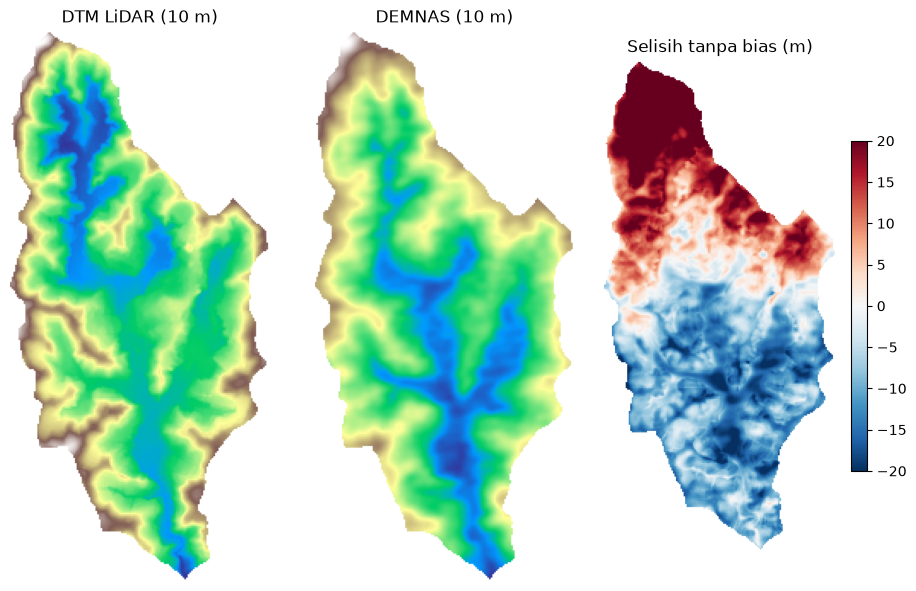

Rata-rata selisih DEMNAS - LiDAR (m)    15.85
Simpangan baku selisih (m)              14.08
RMSE setelah bias dibuang (m)           14.08
Korelasi ketinggian                      0.73
Lereng rata-rata LiDAR 10 m (%)         23.65
Lereng rata-rata DEMNAS 10 m (%)        20.44
Korelasi lereng                          0.52
dtype: float64

In [8]:
def ke10(jalur, metode):
    h = np.full((r1 - r0, c1 - c0), np.nan, 'float32')
    with rasterio.open(jalur) as src:
        a = src.read(1)
        nd = src.nodata
        # berkas DEMNAS tidak menyimpan CRS; koordinatnya geografis
        reproject(a, h, src_transform=src.transform, src_crs=src.crs or 'EPSG:4326', src_nodata=nd, dst_transform=from_origin(xmin, ymaks, 10, 10), dst_crs=CRS, dst_nodata=np.nan, resampling=metode)
    return h
d_lidar = ke10('LiDAR_Kalijambe_Bompon_20222023.tif', Resampling.average)
d_demnas = ke10('DEMNAS_1408-23_v1.0.tif', Resampling.bilinear)
def lereng(z):
    gy, gx = np.gradient(z, 10)
    return 100 * np.hypot(gx, gy)
mm = sah10 & np.isfinite(d_demnas) & np.isfinite(d_lidar)
sel = d_demnas - d_lidar
ringkas = pd.Series({'Rata-rata selisih DEMNAS - LiDAR (m)': sel[mm].mean(), 'Simpangan baku selisih (m)': sel[mm].std(), 'RMSE setelah bias dibuang (m)': np.sqrt(((sel[mm] - sel[mm].mean()) ** 2).mean()),
                     'Korelasi ketinggian': np.corrcoef(d_demnas[mm], d_lidar[mm])[0, 1], 'Lereng rata-rata LiDAR 10 m (%)': lereng(d_lidar)[mm].mean(),
                     'Lereng rata-rata DEMNAS 10 m (%)': lereng(d_demnas)[mm].mean(), 'Korelasi lereng': np.corrcoef(lereng(d_demnas)[mm], lereng(d_lidar)[mm])[0, 1]}).round(2)
ringkas.to_csv('hasil/demnas_vs_lidar.csv', header=['nilai'])

fig, ax = plt.subplots(1, 3, figsize=(9.5, 6))
ax[0].imshow(np.where(mm, d_lidar, np.nan), cmap='terrain'); ax[0].set_title('DTM LiDAR (10 m)')
ax[1].imshow(np.where(mm, d_demnas, np.nan), cmap='terrain'); ax[1].set_title('DEMNAS (10 m)')
im = ax[2].imshow(np.where(mm, sel - sel[mm].mean(), np.nan), cmap='RdBu_r', vmin=-20, vmax=20); ax[2].set_title('Selisih tanpa bias (m)')
plt.colorbar(im, ax=ax[2], shrink=.6)
for a in ax: a.set_axis_off()
plt.tight_layout(); plt.savefig('hasil/demnas_vs_lidar.png', dpi=130); plt.show()
ringkas

**Baca peta selisih di atas.** Selisihnya tidak acak: sekitar 3 m di selatan, lalu naik mulus sampai sekitar 37 m di utara. Pola ini lebih besar daripada pengaruh tajuk. DEMNAS dan Copernicus DEM saling sepakat, sehingga yang paling mungkin miring adalah DTM LiDAR, tetapi penyebabnya belum dapat dipastikan dari data ini. Kemiringan semacam itu juga menjelaskan mengapa pengisian cekungan (*fill sink*) menaikkan bagian utara sampai puluhan meter.

Di sinilah fusi DEM berguna, dan ini juga bentuk penajaman: **gelombang panjang diambil dari DEMNAS, gelombang pendek dari LiDAR.** Rumusnya sama dengan HPF, yaitu LiDAR ditambah selisih versi halus DEMNAS dan versi halus LiDAR.

In [9]:
from scipy.ndimage import gaussian_filter
def halus(z, sigma_m=200, sel=2.5):
    w = np.isfinite(z).astype('float32')
    return gaussian_filter(np.nan_to_num(z) * w, sigma_m / sel) / np.maximum(gaussian_filter(w, sigma_m / sel), 1e-3)

demnas_25 = np.full((baris, kolom), np.nan, 'float32')
with rasterio.open('DEMNAS_1408-23_v1.0.tif') as src:
    reproject(src.read(1), demnas_25, src_transform=src.transform, src_crs=src.crs or 'EPSG:4326', src_nodata=src.nodata, dst_transform=T, dst_crs=CRS, dst_nodata=np.nan, resampling=Resampling.bilinear)
gabungan = dtm + halus(demnas_25) - halus(dtm)
gabungan[~sah] = np.nan
with rasterio.open('hasil/dem_gabungan_2m5.tif', 'w', driver='GTiff', width=kolom, height=baris, count=1, dtype='float32', crs=CRS, transform=T, nodata=np.nan, compress='deflate') as dst:
    dst.write(gabungan.astype('float32'), 1)

def per_zona(z):
    bagi = baris // 3
    return [float(np.nanmean((demnas_25 - z)[a:a + bagi][sah[a:a + bagi]])) for a in (0, bagi, 2 * bagi)]
gy, gx = np.gradient(np.where(sah, dtm, np.nan), 2.5); l1 = 100 * np.hypot(gx, gy)
gy, gx = np.gradient(gabungan, 2.5); l2 = 100 * np.hypot(gx, gy)
ok = np.isfinite(l1) & np.isfinite(l2)
fusi = pd.DataFrame({'Selisih DEMNAS, utara (m)': [per_zona(dtm)[0], per_zona(gabungan)[0]], 'Selisih DEMNAS, tengah (m)': [per_zona(dtm)[1], per_zona(gabungan)[1]], 'Selisih DEMNAS, selatan (m)': [per_zona(dtm)[2], per_zona(gabungan)[2]]}, index=['DTM LiDAR', 'DEM gabungan']).round(2)
fusi.to_csv('hasil/fusi_dem.csv')
print('Lereng 2,5 m: rata-rata beda mutlak LiDAR dan gabungan', round(float(np.abs(l1 - l2)[ok].mean()), 2), 'poin persen | korelasi', round(float(np.corrcoef(l1[ok], l2[ok])[0, 1]), 3), '| lereng rata-rata', round(float(l1[ok].mean()), 1), '%')
fusi

Lereng 2,5 m: rata-rata beda mutlak LiDAR dan gabungan 0.97 poin persen | korelasi 0.998 | lereng rata-rata 26.0 %


,"Selisih DEMNAS, utara (m)","Selisih DEMNAS, tengah (m)","Selisih DEMNAS, selatan (m)"
DTM LiDAR,35.36,12.34,4.96
DEM gabungan,1.12,-0.28,0.28


## 8. Melihat hasilnya

Terakhir, bandingkan citra pada satu potongan, dengan penajaman penuh ke 2,5 m. Perhatikan warna dan bentuknya: bentuk apa yang baru muncul, dan apakah warnanya berubah?

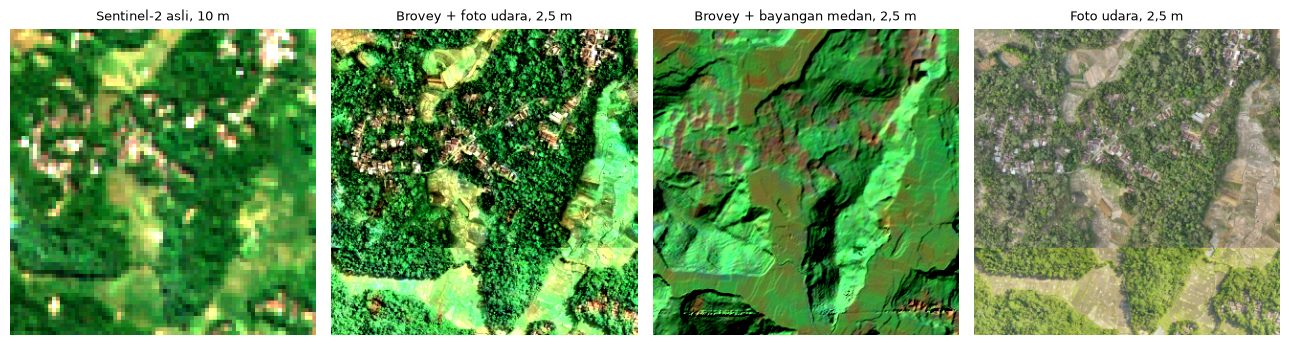

In [10]:
i_rgb = [NAMA['B04'], NAMA['B03'], NAMA['B02']]
lr = s2[i_rgb]
jd = (slice(560, 880), slice(160, 480))   # sel 2,5 m, sekitar 800 x 800 m
def tampil(a):
    lo, hi = np.nanpercentile(s2[i_rgb], 2), np.nanpercentile(s2[i_rgb], 98)
    return np.clip((np.moveaxis(a, 0, -1) - lo) / (hi - lo), 0, 1)
pan_isi = np.where(sah, pan_fu, np.nan), np.where(sah, pan_hs, np.nan)
gambar = {'Sentinel-2 asli, 10 m': np.stack([np.kron(x, np.ones((4, 4))) for x in lr]), 'Brovey + foto udara, 2,5 m': brovey(lr, pan_isi[0], 4),
          'Brovey + bayangan medan, 2,5 m': brovey(lr, pan_isi[1], 4)}
fig, ax = plt.subplots(1, 4, figsize=(13, 3.6))
for a, (judul, c) in zip(ax, gambar.items()):
    a.imshow(tampil(c[(slice(None), *jd)])); a.set_title(judul, fontsize=9); a.set_axis_off()
ax[3].imshow(np.clip(np.moveaxis(fu[[0, 1, 2]][(slice(None), *jd)], 0, -1) / 255, 0, 1)); ax[3].set_title('Foto udara, 2,5 m', fontsize=9); ax[3].set_axis_off()
plt.tight_layout(); plt.savefig('hasil/perbandingan_potongan.png', dpi=140); plt.show()